# Telco Customer Churn — IT3091 Group Project

**Lens:** Churn risk (classification) | **Target:** `Churn`

Run all cells in order (Kernel → Restart & Run All before submitting).

## 1. Understand the Business Problem
A telecom provider wants to reduce customer loss by identifying customers likely to churn.

In [1]:
import os, hashlib, warnings, platform, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from IPython.display import display

import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             balanced_accuracy_score, RocCurveDisplay, PrecisionRecallDisplay, brier_score_loss)
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.base import clone
from scipy.stats import loguniform, randint

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50, "display.width", 160)

In [2]:
# Business context
STAKEHOLDER = "Retention manager at the telecom provider"
DECISION = "Which customers should receive a retention offer this period?"
PRIMARY_LENS = "Churn risk"
SECONDARY_LENS = "High-risk customer profiling"

# Business assumptions (edit to match your group's report)
OFFER_COST   = 20.0   # cost to contact + offer one customer
SAVE_RATE    = 0.30   # fraction of contacted churners who are retained
VALUE_MONTHS = 12      # months of MonthlyCharges kept if a customer is saved

print("Stakeholder:", STAKEHOLDER)
print("Decision:", DECISION)
print("Primary lens:", PRIMARY_LENS, "| Secondary lens:", SECONDARY_LENS)

Stakeholder: Retention manager at the telecom provider
Decision: Which customers should receive a retention offer this period?
Primary lens: Churn risk | Secondary lens: High-risk customer profiling


## 2. Define the ML Problem
Binary classification: predict churn probability, then rank/flag customers.

In [3]:
TASK = "Binary classification (churn probability, used for ranking + a decision threshold)"
UNIT_OF_ANALYSIS = "One customer (snapshot, no dates in the data)"
SUCCESS_METRIC = "PR-AUC / ROC-AUC for ranking quality; expected net benefit at the chosen threshold"

print("Task:", TASK)
print("Unit of analysis:", UNIT_OF_ANALYSIS)
print("Success metric:", SUCCESS_METRIC)

Task: Binary classification (churn probability, used for ranking + a decision threshold)
Unit of analysis: One customer (snapshot, no dates in the data)
Success metric: PR-AUC / ROC-AUC for ranking quality; expected net benefit at the chosen threshold


## 3. Understand the Dataset
Load the CSV, record its fingerprint, and build a data dictionary.

In [4]:
from google.colab import files

uploaded = files.upload()
EXPECTED_FILE = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
assert EXPECTED_FILE in uploaded, f"Please upload {EXPECTED_FILE}"

DATA_PATH = Path(EXPECTED_FILE)

sha = hashlib.sha256(open(DATA_PATH, "rb").read()).hexdigest()
print("File:", DATA_PATH)
print("SHA-256:", sha)
print("Python", platform.python_version(), "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

File: WA_Fn-UseC_-Telco-Customer-Churn.csv
SHA-256: 88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a
Python 3.12.3 | pandas 3.0.2 | scikit-learn 1.8.0


In [5]:
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
display(raw.head())

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
data_dictionary = pd.DataFrame([
 ("customerID","Unique customer identifier","ID"),
 ("gender","Customer gender","categorical"),
 ("SeniorCitizen","Senior citizen flag","binary (numeric)"),
 ("Partner","Has a partner","binary"),
 ("Dependents","Has dependents","binary"),
 ("tenure","Months as a customer","numeric"),
 ("PhoneService","Has phone service","binary"),
 ("MultipleLines","Has multiple phone lines","categorical"),
 ("InternetService","Internet service type","categorical"),
 ("OnlineSecurity","Online security add-on","categorical"),
 ("OnlineBackup","Online backup add-on","categorical"),
 ("DeviceProtection","Device protection add-on","categorical"),
 ("TechSupport","Tech support add-on","categorical"),
 ("StreamingTV","Streams TV","categorical"),
 ("StreamingMovies","Streams movies","categorical"),
 ("Contract","Contract type","categorical"),
 ("PaperlessBilling","Uses paperless billing","binary"),
 ("PaymentMethod","How the customer pays","categorical"),
 ("MonthlyCharges","Current monthly bill","numeric"),
 ("TotalCharges","Total billed to date (stored as text)","numeric"),
 ("Churn","TARGET: customer left","binary"),
], columns=["column","meaning","type"])
display(data_dictionary)

,column,meaning,type
0,customerID,Unique customer identifier,ID
1,gender,Customer gender,categorical
2,SeniorCitizen,Senior citizen flag,binary (numeric)
3,Partner,Has a partner,binary
4,Dependents,Has dependents,binary
5,tenure,Months as a customer,numeric
6,PhoneService,Has phone service,binary
7,MultipleLines,Has multiple phone lines,categorical
8,InternetService,Internet service type,categorical
9,OnlineSecurity,Online security add-on,categorical


## 4. Data Quality Checking
Check duplicates, missing values, wrong types, and consistency between related columns.

In [7]:
print("Duplicate rows:", raw.duplicated().sum())
print("Duplicate customerID:", raw.customerID.duplicated().sum())
print("TotalCharges dtype:", raw.TotalCharges.dtype)

blank = raw.TotalCharges.astype(str).str.strip().eq("")
print("Blank TotalCharges:", blank.sum())
display(raw.loc[blank, ["customerID","tenure","MonthlyCharges","Contract","Churn"]])

Duplicate rows: 0
Duplicate customerID: 0
TotalCharges dtype: str
Blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,Contract,Churn
488,4472-LVYGI,0,52.55,Two year,No
753,3115-CZMZD,0,20.25,Two year,No
936,5709-LVOEQ,0,80.85,Two year,No
1082,4367-NUYAO,0,25.75,Two year,No
1340,1371-DWPAZ,0,56.05,Two year,No
3331,7644-OMVMY,0,19.85,Two year,No
3826,3213-VVOLG,0,25.35,Two year,No
4380,2520-SGTTA,0,20.00,Two year,No
5218,2923-ARZLG,0,19.70,One year,No
6670,4075-WKNIU,0,73.35,Two year,No


In [8]:
# Internet add-on columns that require an active internet service.
ADDONS = ["OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV","StreamingMovies"]
# Check that no phone service means the customer cannot have multiple lines.
c1 = ((raw.MultipleLines == "No phone service") == (raw.PhoneService == "No")).all()
# Check the same rule for every internet add-on column.
c2 = all(((raw[c] == "No internet service") == (raw.InternetService == "No")).all() for c in ADDONS)
# Show whether the phone-service rule is true for all customers.
print("'No phone service' matches PhoneService=No:", c1)
# Show whether the internet-service rule is true for all customers.
print("'No internet service' matches InternetService=No:", c2)

'No phone service' matches PhoneService=No: True
'No internet service' matches InternetService=No: True


In [ ]:
tmp = raw.assign(TotalCharges=pd.to_numeric(raw.TotalCharges.astype(str).str.strip().replace("", np.nan)))
display(tmp[["tenure","MonthlyCharges","TotalCharges"]].describe().round(2))
print("corr(tenure, TotalCharges):", round(tmp.tenure.corr(tmp.TotalCharges), 3))

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7032.00
mean,32.37,64.76,2283.30
std,24.56,30.09,2266.77
min,0.00,18.25,18.80
25%,9.00,35.50,401.45
50%,29.00,70.35,1397.48
75%,55.00,89.85,3794.74
max,72.00,118.75,8684.80


corr(tenure, TotalCharges): 0.826


## 5. Exploratory Data Analysis — quick look (full data)
A first pass on the whole dataset before splitting.

Overall churn rate: 0.2654


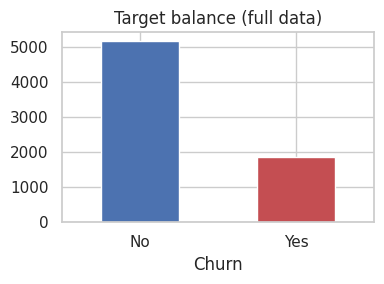

In [10]:
df0 = raw.copy()
df0["TotalCharges"] = pd.to_numeric(df0.TotalCharges.astype(str).str.strip().replace("", np.nan), errors="coerce").fillna(0.0)
df0["ChurnFlag"] = (df0.Churn == "Yes").astype(int)

print("Overall churn rate:", round(df0.ChurnFlag.mean(), 4))
fig, ax = plt.subplots(figsize=(4,3))
df0.Churn.value_counts().plot.bar(ax=ax, color=["#4C72B0","#C44E52"]); ax.set_title("Target balance (full data)")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

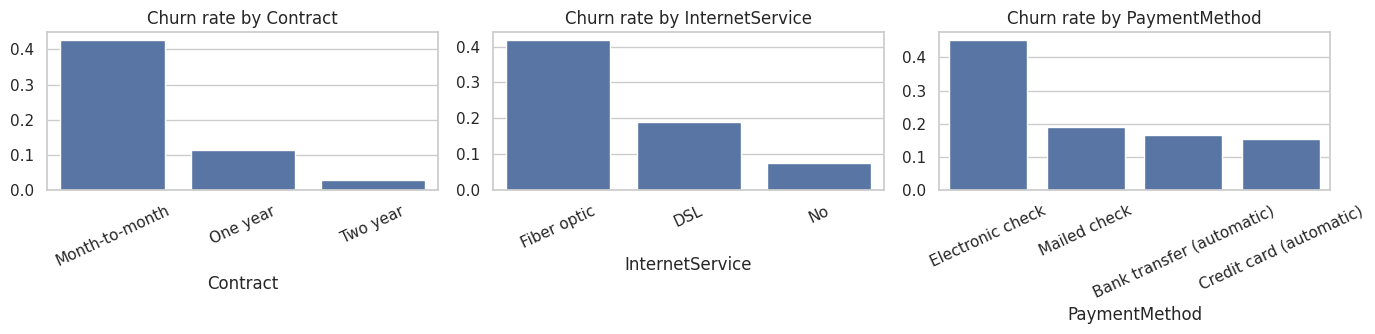

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, c in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    r = df0.groupby(c).ChurnFlag.mean().sort_values(ascending=False)
    sns.barplot(x=r.index.astype(str), y=r.values, ax=ax, color="#4C72B0")
    ax.set_title(f"Churn rate by {c}"); ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

## 6. Train/Test Split
Split 80/20, stratified on Churn, before any deeper analysis or preprocessing.

In [12]:
y = df0["ChurnFlag"]
X = df0.drop(columns=["customerID", "Churn", "ChurnFlag"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "churn rate:", round(y_train.mean(), 4))
print("Test :", X_test.shape, "churn rate:", round(y_test.mean(), 4))

Train: (5634, 19) churn rate: 0.2654
Test : (1409, 19) churn rate: 0.2654


## 7. Exploratory Data Analysis — deeper look (train only)
All further analysis uses the training set only; the test set stays untouched.

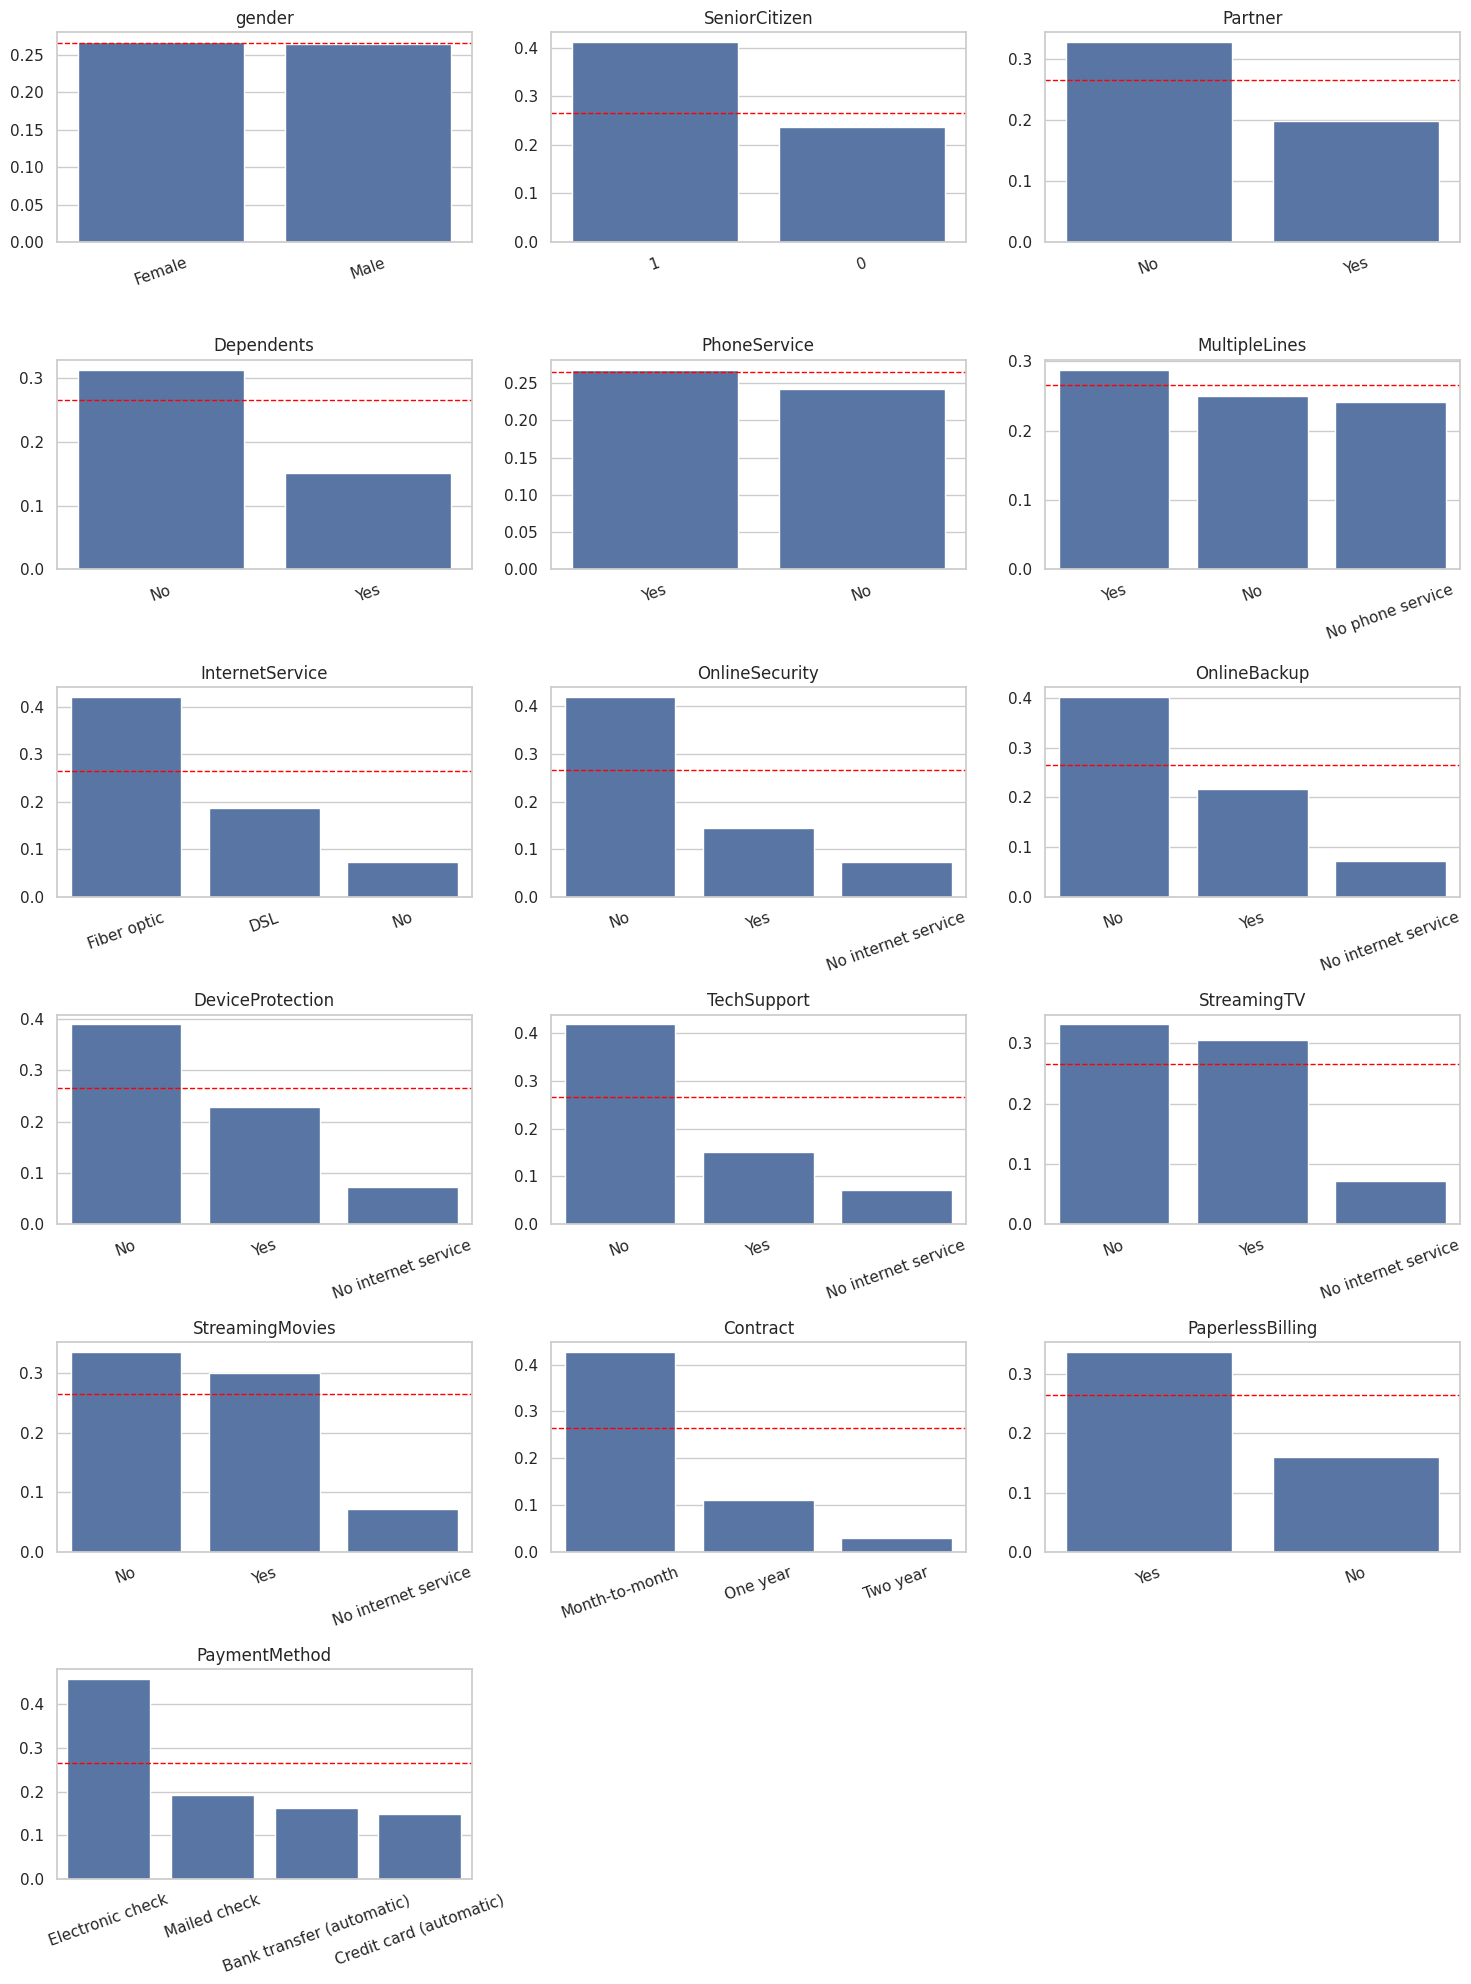

In [13]:
train = X_train.assign(Churn=y_train)
CAT_EDA = ["gender","SeniorCitizen","Partner","Dependents","PhoneService","MultipleLines","InternetService"] + ADDONS + \
          ["Contract","PaperlessBilling","PaymentMethod"]
NUM_EDA = ["tenure","MonthlyCharges","TotalCharges"]

fig, axes = plt.subplots(6, 3, figsize=(15, 20)); overall = train.Churn.mean()
for ax, c in zip(axes.ravel(), CAT_EDA):
    r = train.groupby(c)["Churn"].mean().sort_values(ascending=False)
    sns.barplot(x=r.index.astype(str), y=r.values, ax=ax, color="#4C72B0")
    ax.axhline(overall, color="red", ls="--", lw=1); ax.set_title(c); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=20)
for ax in axes.ravel()[len(CAT_EDA):]: ax.axis("off")
plt.tight_layout(); plt.show()

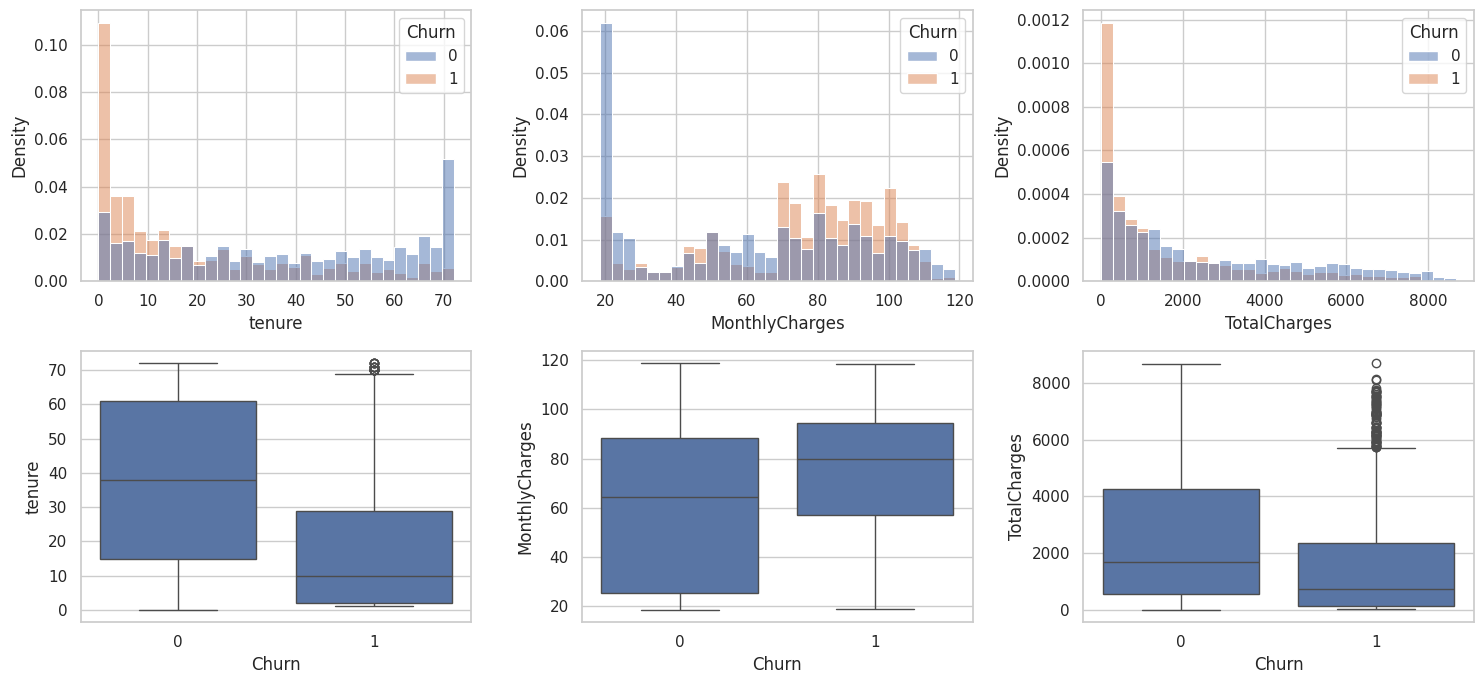

,mean,count
tenure_band,,
0-12,0.473,1737
13-24,0.286,818
25-48,0.202,1290
49-72,0.099,1789


In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for j, c in enumerate(NUM_EDA):
    sns.histplot(data=train, x=c, hue="Churn", bins=30, stat="density", common_norm=False, ax=axes[0, j])
    sns.boxplot(data=train, x="Churn", y=c, ax=axes[1, j])
plt.tight_layout(); plt.show()

train["tenure_band"] = pd.cut(train.tenure, [-1, 12, 24, 48, 72], labels=["0-12","13-24","25-48","49-72"])
display(train.groupby("tenure_band", observed=True).Churn.agg(["mean","count"]).round(3))

In [15]:
rows = []
for c in CAT_EDA:
    ct = pd.crosstab(train[c], train.Churn); chi2, p, dof, _ = stats.chi2_contingency(ct)
    rows.append((c, p, np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))))
for c in NUM_EDA:
    a, b = train.loc[train.Churn == 1, c], train.loc[train.Churn == 0, c]
    u, p = stats.mannwhitneyu(a, b); rows.append((c, p, 1 - 2*u/(len(a)*len(b))))
assoc = pd.DataFrame(rows, columns=["feature","p_value","effect_size"]).sort_values("p_value")
display(assoc.round(4).reset_index(drop=True))

,feature,p_value,effect_size
0,Contract,0.0000,0.4111
1,tenure,0.0000,0.4704
2,OnlineSecurity,0.0000,0.3510
3,TechSupport,0.0000,0.3449
4,InternetService,0.0000,0.3266
5,PaymentMethod,0.0000,0.3111
6,OnlineBackup,0.0000,0.2943
7,DeviceProtection,0.0000,0.2799
8,StreamingMovies,0.0000,0.2317
9,StreamingTV,0.0000,0.2304


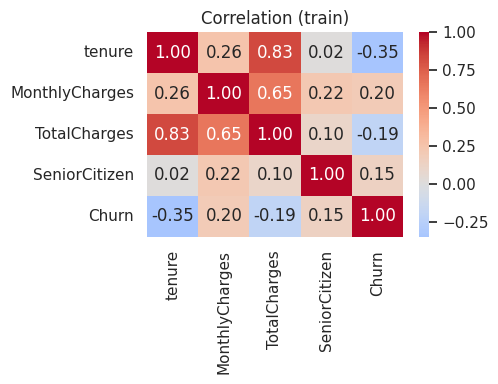

In [16]:
plt.figure(figsize=(5, 4))
sns.heatmap(train[NUM_EDA + ["SeniorCitizen", "Churn"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation (train)"); plt.tight_layout(); plt.show()

## 8. Data Preprocessing
Build a leak-free pipeline: fix TotalCharges, drop the ID column, simplify redundant categories, encode, and scale.

In [17]:
SIMPLIFY = ["MultipleLines"] + ADDONS
NUM_BASE = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
CAT_BASE = ["gender","Partner","Dependents","PhoneService","MultipleLines","InternetService"] + ADDONS + \
           ["Contract","PaperlessBilling","PaymentMethod"]

def make_features(X, extras=(), drop_gender=False):
    X = X.copy()
    for c in SIMPLIFY:
        X[c] = X[c].replace({"No internet service": "No", "No phone service": "No"})
    if "n_addons" in extras:
        X["n_addons"] = (X[ADDONS] == "Yes").sum(axis=1)
    if "autopay" in extras:
        X["autopay"] = X["PaymentMethod"].str.contains("automatic").astype(int)
    if "charge_gap" in extras:
        t = X["tenure"].where(X["tenure"] > 0)
        X["charge_gap"] = (X["MonthlyCharges"] - X["TotalCharges"] / t).fillna(0.0)
    if drop_gender:
        X = X.drop(columns=["gender"])
    return X

In [18]:
def build_pipeline(clf, extras=(), drop_gender=False, scale=True):
    num = NUM_BASE + [e for e in ("n_addons", "charge_gap", "autopay") if e in extras]
    cat = [c for c in CAT_BASE if not (drop_gender and c == "gender")]
    prep = ColumnTransformer(
        [("num", StandardScaler() if scale else "passthrough", num),
         ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat)],
        remainder="drop", verbose_feature_names_out=False)
    steps = [("fe", FunctionTransformer(make_features, kw_args={"extras": tuple(extras), "drop_gender": drop_gender})),
             ("prep", prep), ("clf", clf)]
    return Pipeline(steps)

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
INNER = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "precision": "precision", "recall": "recall", "f1": "f1"}
def run_cv(model, X, y, scoring=SCORING):
    res = cross_validate(model, X, y, cv=CV, scoring=scoring, n_jobs=-1)
    return {k[5:]: v for k, v in res.items() if k.startswith("test_")}
def ms(v): return f"{np.mean(v):.3f} ± {np.std(v):.3f}"
print("Pipeline utilities ready.")

Pipeline utilities ready.


## 9. Feature Engineering
Test candidate features (n_addons, autopay, charge_gap) and whether dropping gender costs anything.

In [19]:
configs = {"base": ((), False), "+n_addons": (("n_addons",), False), "+autopay": (("autopay",), False),
           "+charge_gap": (("charge_gap",), False), "drop gender": ((), True)}
two = {"LogReg": (lambda: LogisticRegression(max_iter=2000), True),
       "HistGB": (lambda: HistGradientBoostingClassifier(random_state=SEED, max_iter=150, learning_rate=0.05), False)}

abl = {}
for cname, (ex, dg) in configs.items():
    for mname, (mk, sc) in two.items():
        abl[(cname, mname)] = run_cv(build_pipeline(mk(), ex, dg, sc), X_train, y_train, {"pr_auc": "average_precision"})

rows = []
for cname in configs:
    r = {"config": cname}
    for mname in two:
        r[f"{mname} PR-AUC"] = ms(abl[(cname, mname)]["pr_auc"])
    rows.append(r)
display(pd.DataFrame(rows))

,config,LogReg PR-AUC,HistGB PR-AUC
0,base,0.661 ± 0.019,0.648 ± 0.026
1,+n_addons,0.661 ± 0.019,0.649 ± 0.023
2,+autopay,0.661 ± 0.019,0.652 ± 0.025
3,+charge_gap,0.659 ± 0.019,0.643 ± 0.026
4,drop gender,0.661 ± 0.019,0.650 ± 0.025


In [20]:
EXTRAS = tuple(e for e, k in [("n_addons", "+n_addons"), ("autopay", "+autopay"), ("charge_gap", "+charge_gap")]
               if all(abl[(k, m)]["pr_auc"].mean() > abl[("base", m)]["pr_auc"].mean() for m in two))
DROP_GENDER = all(abl[("drop gender", m)]["pr_auc"].mean() >= abl[("base", m)]["pr_auc"].mean() - 0.001 for m in two)
print("Kept engineered features:", EXTRAS)
print("Drop gender:", DROP_GENDER)

Kept engineered features: ('n_addons',)
Drop gender: True


## 10. Handle Class Imbalance
Compare no reweighting vs class_weight='balanced'.

In [21]:
variants = {
  "no reweighting": build_pipeline(LogisticRegression(max_iter=2000), EXTRAS, DROP_GENDER, True),
  "class_weight=balanced": build_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced"), EXTRAS, DROP_GENDER, True),
}
imb = {n: run_cv(m, X_train, y_train) for n, m in variants.items()}
display(pd.DataFrame({n: {k: ms(imb[n][k]) for k in ["roc_auc","pr_auc","recall","precision","f1"]} for n in imb}).T)

,roc_auc,pr_auc,recall,precision,f1
no reweighting,0.846 ± 0.013,0.661 ± 0.019,0.544 ± 0.041,0.655 ± 0.029,0.594 ± 0.031
class_weight=balanced,0.846 ± 0.012,0.659 ± 0.019,0.803 ± 0.037,0.519 ± 0.019,0.630 ± 0.022


In [22]:
base_n, w_n = "no reweighting", "class_weight=balanced"
USE_WEIGHTS = imb[w_n]["pr_auc"].mean() > imb[base_n]["pr_auc"].mean() + imb[base_n]["pr_auc"].std()
CLASS_WEIGHT = "balanced" if USE_WEIGHTS else None
print("Class weight used in final models:", CLASS_WEIGHT)

Class weight used in final models: None


## 11. Build Baseline
A Dummy classifier (majority class) sets the floor; logistic regression is the sensible baseline.

In [23]:
def all_models():
    cw = CLASS_WEIGHT
    return {
     "Dummy":        build_pipeline(DummyClassifier(strategy="prior"), EXTRAS, DROP_GENDER, False),
     "LogReg":       build_pipeline(LogisticRegression(max_iter=2000, class_weight=cw), EXTRAS, DROP_GENDER, True),
     "DecisionTree": build_pipeline(DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, class_weight=cw, random_state=SEED), EXTRAS, DROP_GENDER, False),
     "RandomForest": build_pipeline(RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight=cw, random_state=SEED, n_jobs=-1), EXTRAS, DROP_GENDER, False),
     "HistGB":       build_pipeline(HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, class_weight=cw, random_state=SEED), EXTRAS, DROP_GENDER, False),
    }

baseline_cv = run_cv(all_models()["Dummy"], X_train, y_train, {"roc_auc":"roc_auc","pr_auc":"average_precision","accuracy":"accuracy"})
print("Dummy baseline (majority class):")
print("  ROC-AUC :", ms(baseline_cv["roc_auc"]))
print("  PR-AUC  :", ms(baseline_cv["pr_auc"]))
print("  Accuracy:", ms(baseline_cv["accuracy"]), " (= always predicting 'no churn')")

Dummy baseline (majority class):
  ROC-AUC : 0.500 ± 0.000
  PR-AUC  : 0.265 ± 0.000
  Accuracy: 0.735 ± 0.000  (= always predicting 'no churn')


## 12. Train Multiple ML Models
Run the same 5-fold CV for every model, with default hyperparameters.

In [24]:
untuned = {n: run_cv(m, X_train, y_train, {"roc_auc":"roc_auc","pr_auc":"average_precision","accuracy":"accuracy",
                                            "precision":"precision","recall":"recall","f1":"f1"})
           for n, m in all_models().items()}
tbl = pd.DataFrame({n: {k: ms(v[k]) for k in ["roc_auc","pr_auc","accuracy","precision","recall","f1"]} for n, v in untuned.items()}).T
display(tbl)

,roc_auc,pr_auc,accuracy,precision,recall,f1
Dummy,0.500 ± 0.000,0.265 ± 0.000,0.735 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
LogReg,0.846 ± 0.013,0.661 ± 0.019,0.803 ± 0.013,0.655 ± 0.029,0.544 ± 0.041,0.594 ± 0.031
DecisionTree,0.829 ± 0.011,0.613 ± 0.023,0.790 ± 0.010,0.624 ± 0.024,0.527 ± 0.041,0.570 ± 0.027
RandomForest,0.844 ± 0.010,0.658 ± 0.022,0.800 ± 0.012,0.666 ± 0.035,0.498 ± 0.021,0.569 ± 0.023
HistGB,0.836 ± 0.008,0.644 ± 0.022,0.799 ± 0.013,0.650 ± 0.035,0.526 ± 0.022,0.581 ± 0.025


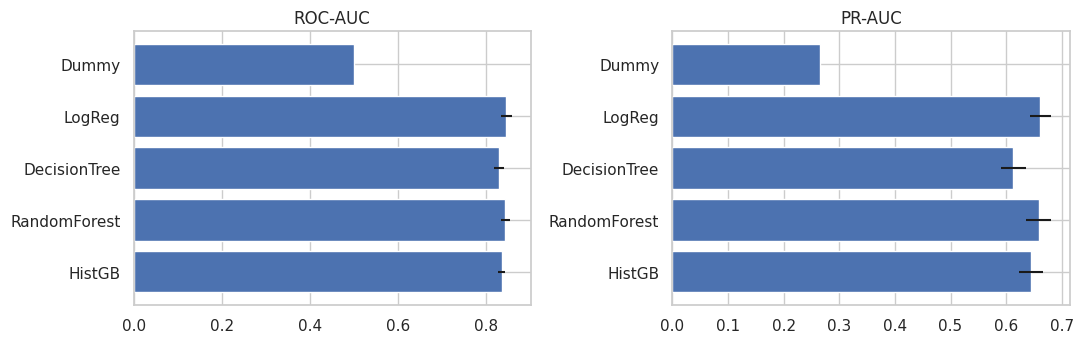

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, k, t in zip(axes, ["roc_auc", "pr_auc"], ["ROC-AUC", "PR-AUC"]):
    ax.barh(list(untuned), [untuned[n][k].mean() for n in untuned], xerr=[untuned[n][k].std() for n in untuned], color="#4C72B0")
    ax.set_title(t); ax.invert_yaxis()
plt.tight_layout(); plt.show()

## 13. Tune Models
RandomizedSearchCV for all four models, evaluated with nested cross-validation (tuning happens only inside training folds).

In [26]:
SPACES = {
 "LogReg":       {"clf__C": loguniform(1e-3, 1e2)},
 "DecisionTree": {"clf__max_depth": randint(2, 12), "clf__min_samples_leaf": randint(5, 100), "clf__criterion": ["gini", "entropy"]},
 "RandomForest": {"clf__n_estimators": randint(150, 400), "clf__max_depth": randint(4, 16), "clf__min_samples_leaf": randint(2, 30),
                  "clf__max_features": ["sqrt", 0.3, 0.5]},
 "HistGB":       {"clf__learning_rate": loguniform(0.02, 0.2), "clf__max_iter": randint(80, 300), "clf__max_leaf_nodes": randint(6, 32),
                  "clf__min_samples_leaf": randint(10, 80), "clf__l2_regularization": loguniform(1e-3, 10)},
}
N_ITER = {"LogReg": 10, "DecisionTree": 15, "RandomForest": 12, "HistGB": 12}
TUNE = list(SPACES)

def make_search(name, cv=INNER):
    return RandomizedSearchCV(all_models()[name], SPACES[name], n_iter=N_ITER[name], scoring="average_precision",
                              cv=cv, random_state=SEED, n_jobs=-1, refit=True)

In [27]:
nested, t0 = {}, time.time()
for name in TUNE:
    res = cross_validate(make_search(name), X_train, y_train, cv=CV, scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"}, n_jobs=1)
    nested[name] = {"roc_auc": res["test_roc_auc"], "pr_auc": res["test_pr_auc"]}
    print(f"{name:13s} nested PR-AUC {ms(nested[name]['pr_auc'])} | ROC-AUC {ms(nested[name]['roc_auc'])}   ({time.time()-t0:.0f}s elapsed)")

LogReg        nested PR-AUC 0.661 ± 0.019 | ROC-AUC 0.846 ± 0.013   (6s elapsed)


DecisionTree  nested PR-AUC 0.622 ± 0.026 | ROC-AUC 0.823 ± 0.013   (15s elapsed)


RandomForest  nested PR-AUC 0.664 ± 0.019 | ROC-AUC 0.847 ± 0.010   (148s elapsed)


HistGB        nested PR-AUC 0.659 ± 0.019 | ROC-AUC 0.846 ± 0.012   (193s elapsed)


In [28]:
order = ["LogReg", "DecisionTree", "RandomForest", "HistGB"]
best_name = max(TUNE, key=lambda n: nested[n]["pr_auc"].mean())
se_best = nested[best_name]["pr_auc"].std() / np.sqrt(len(nested[best_name]["pr_auc"]))
eligible = [n for n in order if nested[n]["pr_auc"].mean() >= nested[best_name]["pr_auc"].mean() - se_best]
FINAL_NAME = eligible[0]
print("Best mean PR-AUC:", best_name, "| Within 1 SE:", eligible, "| Chosen (simplest eligible):", FINAL_NAME)

Best mean PR-AUC: RandomForest | Within 1 SE: ['LogReg', 'RandomForest', 'HistGB'] | Chosen (simplest eligible): LogReg


In [29]:
final_search = make_search(FINAL_NAME, cv=CV)
final_search.fit(X_train, y_train)
final_model = final_search.best_estimator_
print("Final model:", FINAL_NAME)
print("Best hyper-parameters:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in final_search.best_params_.items()})

Final model: LogReg
Best hyper-parameters: {'clf__C': np.float64(4.5706)}


## 14. Evaluate Models
Score the final model on the untouched test set with several metrics, not accuracy alone.

In [30]:
p_test = final_model.predict_proba(X_test)[:, 1]
pred05 = (p_test >= 0.5).astype(int)
yt = y_test.values

print("ROC-AUC :", round(roc_auc_score(yt, p_test), 3))
print("PR-AUC  :", round(average_precision_score(yt, p_test), 3))
print("F1 @0.5 :", round(f1_score(yt, pred05), 3))
print("Brier   :", round(brier_score_loss(yt, p_test), 3))

ROC-AUC : 0.842
PR-AUC  : 0.631
F1 @0.5 : 0.607
Brier   : 0.138


In [31]:
comp = {}
for n_, mdl in all_models().items():
    if n_ == "Dummy": continue
    mm = clone(mdl).fit(X_train, y_train) if n_ != FINAL_NAME else final_model
    s = mm.predict_proba(X_test)[:, 1]
    comp[n_] = {"ROC-AUC": roc_auc_score(yt, s), "PR-AUC": average_precision_score(yt, s)}
display(pd.DataFrame(comp).T.round(3))

,ROC-AUC,PR-AUC
LogReg,0.842,0.631
DecisionTree,0.834,0.626
RandomForest,0.844,0.652
HistGB,0.832,0.634


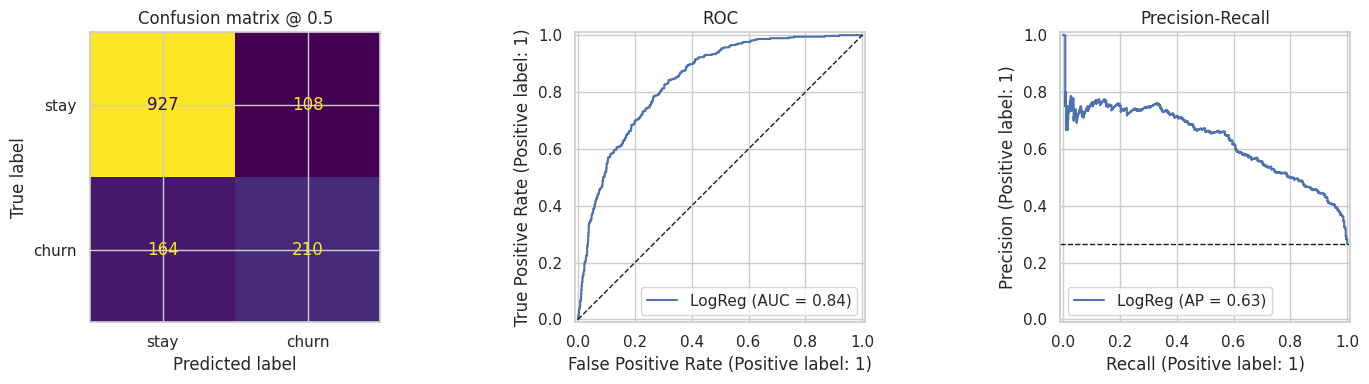

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay(confusion_matrix(yt, pred05), display_labels=["stay","churn"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix @ 0.5")
RocCurveDisplay.from_predictions(yt, p_test, ax=axes[1], name=FINAL_NAME); axes[1].plot([0,1],[0,1],"k--",lw=1); axes[1].set_title("ROC")
PrecisionRecallDisplay.from_predictions(yt, p_test, ax=axes[2], name=FINAL_NAME); axes[2].axhline(yt.mean(), color="k", ls="--", lw=1); axes[2].set_title("Precision-Recall")
plt.tight_layout(); plt.show()

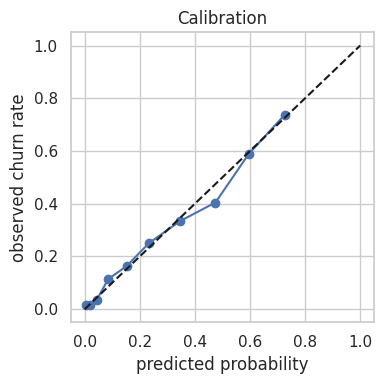

In [33]:
fp, mp = calibration_curve(yt, p_test, n_bins=10, strategy="quantile")
plt.figure(figsize=(4,4)); plt.plot(mp, fp, "o-"); plt.plot([0,1],[0,1],"k--")
plt.xlabel("predicted probability"); plt.ylabel("observed churn rate"); plt.title("Calibration"); plt.tight_layout(); plt.show()

## 15. Threshold Analysis
Choose an operating threshold using out-of-fold training predictions and expected net benefit.

In [34]:
def net_benefit_per_1000(y_true, flagged, monthly, save_rate=SAVE_RATE, offer_cost=OFFER_COST):
    y_true, flagged, monthly = np.asarray(y_true), np.asarray(flagged).astype(bool), np.asarray(monthly)
    gain = (y_true[flagged] * save_rate * VALUE_MONTHS * monthly[flagged]).sum() - offer_cost * flagged.sum()
    return 1000 * gain / len(y_true)

oof = cross_val_predict(clone(final_model), X_train, y_train, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
grid = np.round(np.arange(0.02, 0.91, 0.01), 2)
mc_train = X_train["MonthlyCharges"].values
curve = pd.DataFrame({
    "threshold": grid,
    "precision": [precision_score(y_train, oof >= t, zero_division=0) for t in grid],
    "recall":    [recall_score(y_train, oof >= t) for t in grid],
    "f1":        [f1_score(y_train, oof >= t) for t in grid],
    "benefit_per_1000": [net_benefit_per_1000(y_train, oof >= t, mc_train) for t in grid]})
THRESHOLD = float(curve.loc[curve.benefit_per_1000.idxmax(), "threshold"])
print("Chosen threshold (max expected net benefit):", THRESHOLD)
display(curve[curve.threshold.isin([0.1,0.2,0.3,THRESHOLD,0.4,0.5,0.6])].drop_duplicates("threshold").round(3))

Chosen threshold (max expected net benefit): 0.07


,threshold,precision,recall,f1,benefit_per_1000
5,0.07,0.376,0.963,0.540,55651.157
8,0.10,0.400,0.938,0.561,55178.165
18,0.20,0.474,0.858,0.611,53368.491
28,0.30,0.541,0.769,0.635,49889.872
38,0.40,0.593,0.662,0.626,44526.436
48,0.50,0.655,0.546,0.596,38079.148
58,0.60,0.715,0.399,0.512,28487.039


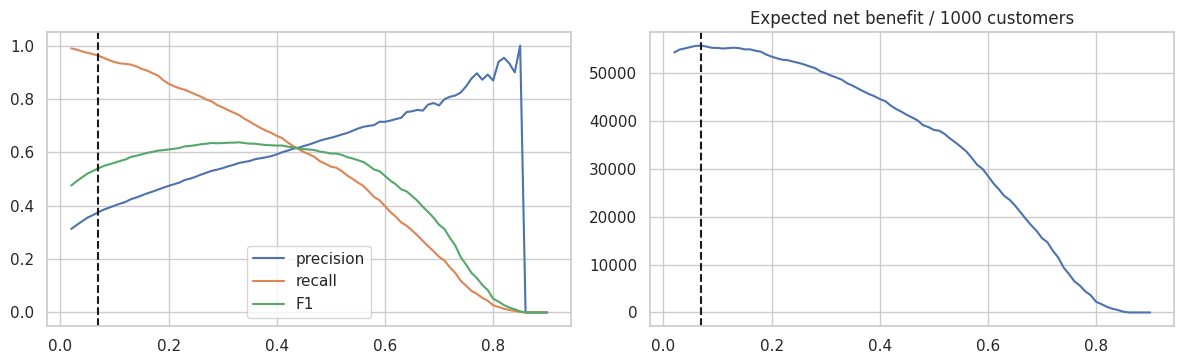

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(curve.threshold, curve.precision, label="precision"); axes[0].plot(curve.threshold, curve.recall, label="recall")
axes[0].plot(curve.threshold, curve.f1, label="F1"); axes[0].axvline(THRESHOLD, color="k", ls="--"); axes[0].legend()
axes[1].plot(curve.threshold, curve.benefit_per_1000); axes[1].axvline(THRESHOLD, color="k", ls="--"); axes[1].set_title("Expected net benefit / 1000 customers")
plt.tight_layout(); plt.show()

In [36]:
pred = (p_test >= THRESHOLD).astype(int)
print("At the chosen threshold, on the TEST set:")
print("  Precision:", round(precision_score(yt, pred), 3))
print("  Recall   :", round(recall_score(yt, pred), 3))
print("  F1       :", round(f1_score(yt, pred), 3))
print("  Share of customers flagged:", round(pred.mean(), 3))

At the chosen threshold, on the TEST set:
  Precision: 0.379
  Recall   : 0.973
  F1       : 0.546
  Share of customers flagged: 0.681


## 16. Explain Important Features
Permutation importance, coefficients (if linear), and a readable surrogate tree.

In [37]:
pi = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"feature": X_test.columns, "importance": pi.importances_mean, "std": pi.importances_std}) \
        .sort_values("importance", ascending=False).reset_index(drop=True)
display(imp.head(12).round(4))

,feature,importance,std
0,tenure,0.1757,0.0051
1,InternetService,0.1707,0.0143
2,MonthlyCharges,0.0785,0.0088
3,Contract,0.0346,0.0040
4,TotalCharges,0.0161,0.0025
5,StreamingMovies,0.0078,0.0024
6,StreamingTV,0.0074,0.0031
7,MultipleLines,0.0043,0.0018
8,PaymentMethod,0.0032,0.0016
9,PaperlessBilling,0.0028,0.0016


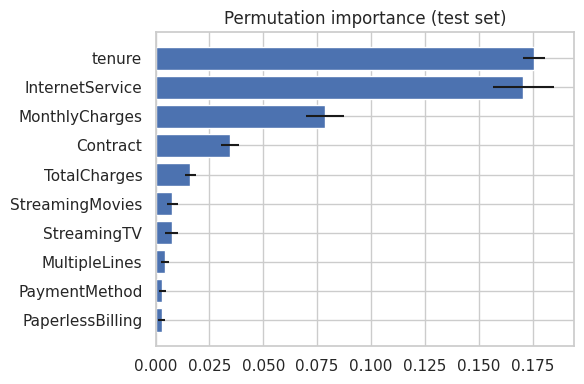

In [38]:
top = imp.head(10).iloc[::-1]
plt.figure(figsize=(6,4)); plt.barh(top.feature, top.importance, xerr=top["std"], color="#4C72B0")
plt.title("Permutation importance (test set)"); plt.tight_layout(); plt.show()

In [39]:
clf = final_model.named_steps["clf"]
names = final_model.named_steps["prep"].get_feature_names_out()
if hasattr(clf, "coef_"):
    coefs = pd.Series(clf.coef_[0], index=names).sort_values()
    display(pd.concat([coefs.head(6), coefs.tail(6)]).round(3).to_frame("coefficient"))

,coefficient
InternetService_No,-2.205
tenure,-1.291
MonthlyCharges,-1.215
Contract_Two year,-1.077
OnlineSecurity_Yes,-0.595
TechSupport_Yes,-0.543
Contract_Month-to-month,0.292
PaperlessBilling_Yes,0.370
MultipleLines_Yes,0.484
TotalCharges,0.571


In [40]:
Z_train = final_model.named_steps["prep"].transform(final_model.named_steps["fe"].transform(X_train))
sur = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=SEED).fit(Z_train, (oof >= THRESHOLD).astype(int))
print(export_text(sur, feature_names=list(names)))

|--- Contract_Month-to-month <= 0.50
|   |--- InternetService_Fiber optic <= 0.50
|   |   |--- Contract_Two year <= 0.50
|   |   |   |--- class: 0
|   |   |--- Contract_Two year >  0.50
|   |   |   |--- class: 0
|   |--- InternetService_Fiber optic >  0.50
|   |   |--- Contract_Two year <= 0.50
|   |   |   |--- class: 1
|   |   |--- Contract_Two year >  0.50
|   |   |   |--- class: 0
|--- Contract_Month-to-month >  0.50
|   |--- tenure <= -0.33
|   |   |--- tenure <= -0.49
|   |   |   |--- class: 1
|   |   |--- tenure >  -0.49
|   |   |   |--- class: 1
|   |--- tenure >  -0.33
|   |   |--- MonthlyCharges <= -1.17
|   |   |   |--- class: 0
|   |   |--- MonthlyCharges >  -1.17
|   |   |   |--- class: 1



## 17. High-Risk Customer Profiling
Describe the flagged group vs the rest (test set).

In [41]:
flag = pd.Series(pred == 1, index=X_test.index)
prof = pd.DataFrame({
 "flagged": {"share of customers": flag.mean(), "actual churn rate": y_test[flag].mean(),
             "median tenure": X_test.tenure[flag].median(), "median MonthlyCharges": X_test.MonthlyCharges[flag].median(),
             "% month-to-month": (X_test.Contract[flag]=="Month-to-month").mean(),
             "% fibre optic": (X_test.InternetService[flag]=="Fiber optic").mean(),
             "% electronic check": (X_test.PaymentMethod[flag]=="Electronic check").mean()},
 "not flagged": {"share of customers": 1-flag.mean(), "actual churn rate": y_test[~flag].mean(),
             "median tenure": X_test.tenure[~flag].median(), "median MonthlyCharges": X_test.MonthlyCharges[~flag].median(),
             "% month-to-month": (X_test.Contract[~flag]=="Month-to-month").mean(),
             "% fibre optic": (X_test.InternetService[~flag]=="Fiber optic").mean(),
             "% electronic check": (X_test.PaymentMethod[~flag]=="Electronic check").mean()}})
display(prof.round(3))

,flagged,not flagged
share of customers,0.681,0.319
actual churn rate,0.379,0.022
median tenure,16.000,57.000
median MonthlyCharges,75.300,45.250
% month-to-month,0.781,0.051
% fibre optic,0.585,0.114
% electronic check,0.467,0.058


## 18. Business Recommendations
Compare campaign policies and their expected net benefit under the stated assumptions.

In [42]:
mc_test = X_test["MonthlyCharges"].values
rank = np.argsort(-p_test)
rows = []
for k in [0.10, 0.20, 0.30, 0.40]:
    m = int(round(k * len(yt))); flagged = np.zeros(len(yt), bool); flagged[rank[:m]] = True
    rows.append({"policy": f"top {int(k*100)}%", "contacted": m, "churners reached": int(yt[flagged].sum()),
                 "precision": yt[flagged].mean(), "net benefit / 1000": net_benefit_per_1000(yt, flagged, mc_test)})
rows.append({"policy": f"score >= {THRESHOLD:.2f}", "contacted": int(flag.sum()), "churners reached": int(yt[flag].sum()),
             "precision": yt[flag].mean(), "net benefit / 1000": net_benefit_per_1000(yt, flag.values, mc_test)})
rows.append({"policy": "contact everyone", "contacted": len(yt), "churners reached": int(yt.sum()),
             "precision": yt.mean(), "net benefit / 1000": net_benefit_per_1000(yt, np.ones(len(yt), bool), mc_test)})
policy = pd.DataFrame(rows)
display(policy.round(2))

,policy,contacted,churners reached,precision,net benefit / 1000
0,top 10%,141,104,0.74,19512.22
1,top 20%,282,187,0.66,33758.58
2,top 30%,423,244,0.58,42490.86
3,top 40%,564,291,0.52,49009.48
4,score >= 0.07,960,364,0.38,54060.09
5,contact everyone,1409,374,0.27,49534.17


## 19. Responsible AI + Limitations
Document fairness checks and key limitations.

In [43]:
def subgroup_table(series, name):
    rows = []
    for gval in sorted(series.unique(), key=str):
        m = (series == gval).values
        yy, pp = yt[m], pred[m]
        rows.append({name: gval, "n": int(m.sum()), "churn_rate": yy.mean(), "flagged_rate": pp.mean(),
                     "recall": recall_score(yy, pp, zero_division=0)})
    return pd.DataFrame(rows).round(3)

display(subgroup_table(X_test.SeniorCitizen, "SeniorCitizen"))
display(subgroup_table(X_test.Contract, "Contract"))

,SeniorCitizen,n,churn_rate,flagged_rate,recall
0,0,1187,0.233,0.649,0.967
1,1,222,0.441,0.856,0.990


,Contract,n,churn_rate,flagged_rate,recall
0,Month-to-month,773,0.426,0.970,0.997
1,One year,300,0.120,0.550,0.889
2,Two year,336,0.027,0.134,0.444


**Limitations (fill in your own wording):**
- Fictional/sample data (IBM); no external validation.
- Snapshot only, no dates; churn time window is ambiguous.
- No real cost/CLTV data — money figures rely on stated assumptions.
- Associations shown in EDA are not proof of causation.
- Small test set — metrics have sampling uncertainty.

## 20. Final Notebook + Demo
Export artifacts for the report and confirm reproducibility.

In [44]:
import joblib
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
data_dictionary.to_csv(OUT / "data_dictionary.csv", index=False)
tbl.to_csv(OUT / "model_comparison.csv")
policy.to_csv(OUT / "campaign_policy_table.csv", index=False)
joblib.dump(final_model, OUT / "final_model.joblib")

print("Dataset SHA-256:", sha)
print("Random seed:", SEED)
print("Final model:", FINAL_NAME, "| Threshold:", THRESHOLD)
print("Files written:", sorted(p.name for p in OUT.iterdir() if p.is_file()))

Dataset SHA-256: 88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a
Random seed: 42
Final model: LogReg | Threshold: 0.07
Files written: ['campaign_policy_table.csv', 'data_dictionary.csv', 'final_model.joblib', 'model_comparison.csv']


### Checklist before submission
- [ ] Kernel → Restart & Run All — confirm no errors
- [ ] Every number in the report matches a notebook output
- [x] **Final Report** written (problem framing, EDA insights, preprocessing decisions, model comparison, evaluation, recommendation, limitations)
- [x] **3-minute demo video** recorded and uploaded to YouTube
- [ ] Dataset link + fingerprint (SHA-256 above) included in the report
- [x] AI-use declared honestly
- [ ] Individual Personal Learning Journey (1 page, each member)